# Lab 05 — Computational notebook

Use this notebook for executable analysis and output generation. Narrative answers and captions belong only in `REPORT.md`. Follow the tasks in `README.md`; this scaffold is intentionally incomplete.

In [1]:
from pathlib import Path
import sys, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "solution.py").exists():
    raise RuntimeError("Open the notebook from the lab root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src import solution as s

OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
names = ["Mira", "Asad", "Hajjāj", "Nasr"]
expected = ["I", "II", "III", "IV"]
raw = {key: (ROOT / "data" / f"{key}.txt").read_text(encoding="utf-8") for key in ["journey", "survey"]}


## Source audit and extraction

Add analysis code for T1–T2. Enable the function calls after implementation.

In [2]:
# T1: byte-level audit and auditable chapter extraction
layouts = {"journey": "travel", "survey": "survey"}
audit_rows = []
for book, layout in layouts.items():
    path = ROOT / "data" / f"{book}.txt"
    payload = path.read_bytes()
    audit_rows.append({"file": path.name, "layout": layout, "byte_count": len(payload),
                       "sha256": hashlib.sha256(payload).hexdigest(), "expected_chapters": "I,II,III,IV"})
pd.DataFrame(audit_rows).to_csv(OUT / "source_audit.csv", index=False)

# Exact source excerpts demonstrate why the boundaries matter.
boundary_rows = [
    {"file": "journey.txt", "boundary_type": "cover/front matter", "example": "The cover mentions Mira and Asad; cover mentions are not evidence."},
    {"file": "journey.txt", "boundary_type": "endnote", "example": "[1] Mira appears here only in an editorial note."},
    {"file": "survey.txt", "boundary_type": "bibliography", "example": "Mira, Asad, Hajjāj and Nasr appear in this excluded bibliography."},
    {"file": "survey.txt", "boundary_type": "inline footnote marker", "example": "II. THE RIVER ARCHIVE.[4]"},
]
pd.DataFrame(boundary_rows).to_csv(OUT / "boundary_examples.csv", index=False)

records = {book: s.extract_chapters(raw[book], layout, expected) for book, layout in layouts.items()}
clean = {book: [s.clean_text(r["text"]) for r in rows] for book, rows in records.items()}
chapter_rows = []
for book, rows in records.items():
    for rec, cleaned in zip(rows, clean[book]):
        chapter_rows.append({"book_id": book, "chapter": rec["chapter"], "roman": rec["roman"],
                             "title": rec["title"], "raw_text": rec["text"], "clean_text": cleaned})
pd.DataFrame(chapter_rows).to_csv(OUT / "chapters.csv", index=False)

# Parser rejection checks: absent end marker and a duplicated/missing chapter heading.
checks = []
for label, bad_text in [("missing end marker", raw["journey"].replace("*** END OF TEACHING TEXT JOURNEY ***", "")),
                        ("duplicated/missing chapter", raw["journey"].replace("CHAPTER III.", "CHAPTER II."))]:
    try:
        s.extract_chapters(bad_text, "travel", expected)
        checks.append({"case": label, "exception_type": "NONE", "message": "No exception"})
    except Exception as exc:
        checks.append({"case": label, "exception_type": type(exc).__name__, "message": str(exc)})
pd.DataFrame(checks).to_csv(OUT / "parser_checks.csv", index=False)

cleaning = [
    {"file": "journey.txt", "raw_excerpt": "Haj_j_āj sent a message.[1]", "clean_excerpt": s.clean_text("Haj_j_āj sent a message.[1]")},
    {"file": "survey.txt", "raw_excerpt": "The label also contains the decomposed form Hajja\u0304j, retaining the accent.",
     "clean_excerpt": s.clean_text("The label also contains the decomposed form Hajja\u0304j, retaining the accent.")},
]
pd.DataFrame(cleaning).to_csv(OUT / "cleaning_examples.csv", index=False)


## Count tables and independent checks

In [3]:
# T3: chapter/name counts, independent check, cumulative sums and weighted book rates
matrices = {book: s.count_names(clean[book], names) for book in layouts}
summary = pd.concat([s.summarize_chapters(book, records[book], names) for book in layouts], ignore_index=True)
summary.to_csv(OUT / "chapter_summary.csv", index=False)

# Mirabel is a deliberate near-match, not a Mira hit.
mirabel_check = int(s.count_names(["Mirabel"], ["Mira"])[0, 0])
assert mirabel_check == 0

manual_text = clean["journey"][0]
manual_expected = {"Mira": 4, "Asad": 1, "Hajjāj": 1, "Nasr": 1}
manual_rows = []
for j, name in enumerate(names):
    computed = int(matrices["journey"][0, j])
    manual_rows.append({"book_id": "journey", "chapter": 1, "name": name,
                        "manual_expected": manual_expected[name], "computed": computed,
                        "match": manual_expected[name] == computed})
assert all(row["match"] for row in manual_rows)
pd.DataFrame(manual_rows).to_csv(OUT / "manual_check.csv", index=False)

cumulative_rows = []
for book in layouts:
    cumulative = np.cumsum(matrices[book], axis=0)
    for i in range(cumulative.shape[0]):
        for j, name in enumerate(names):
            cumulative_rows.append({"book_id": book, "chapter": i+1, "name": name,
                                    "cumulative_mentions": int(cumulative[i, j])})
    assert np.array_equal(cumulative[-1], matrices[book].sum(axis=0))
pd.DataFrame(cumulative_rows).to_csv(OUT / "cumulative_mentions.csv", index=False)

# One denominator per chapter: do not sum the repeated word_count rows across names.
book_rows = []
for book in layouts:
    one_per_chapter = summary[summary.book_id == book].drop_duplicates(subset=["chapter"])
    total_words = int(one_per_chapter.word_count.sum())
    for name in names:
        total_mentions = int(summary[(summary.book_id == book) & (summary.name == name)].mentions.sum())
        book_rows.append({"book_id": book, "name": name, "mentions": total_mentions,
                          "word_count": total_words, "mentions_per_1000_words": 1000*total_mentions/total_words})
book_summary = pd.DataFrame(book_rows)
book_summary.to_csv(OUT / "book_summary.csv", index=False)


## Figures and reproduction

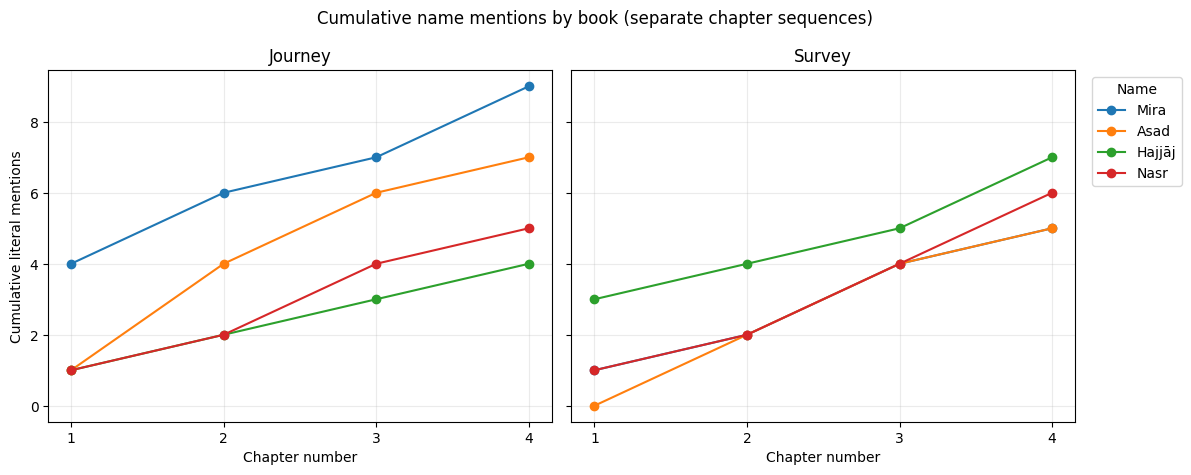

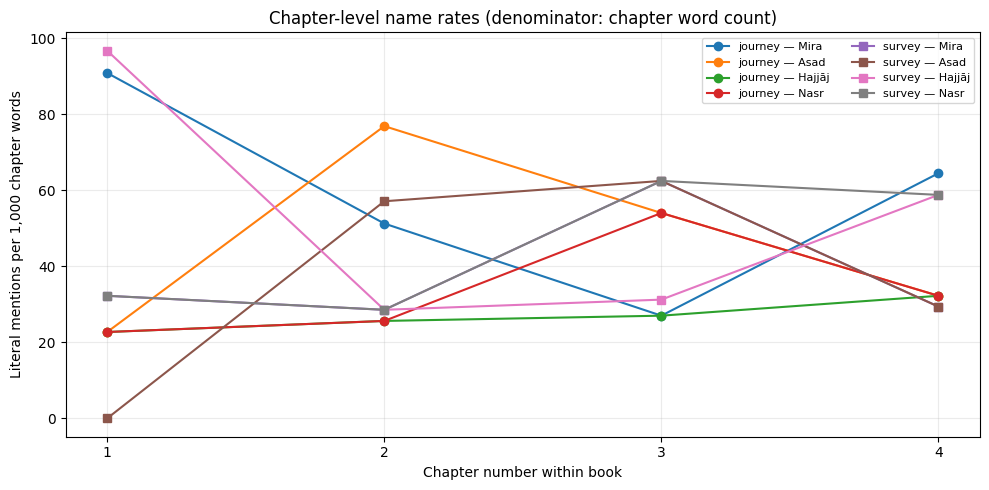

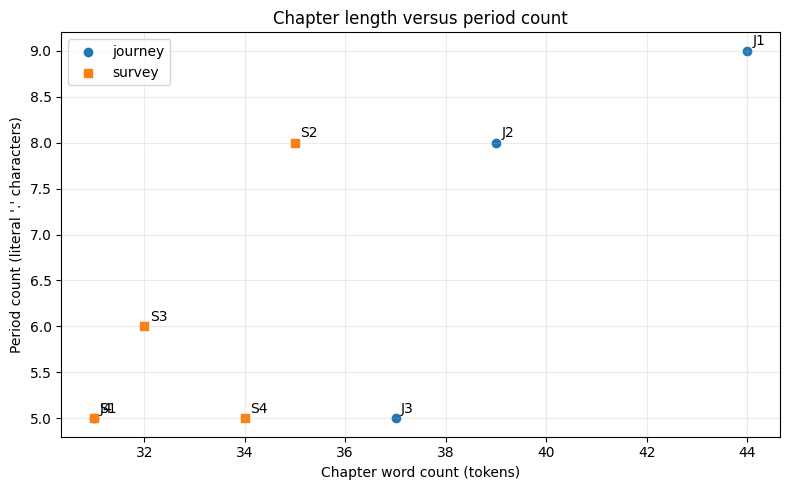

362

In [4]:
# T4: plots use the saved analysis tables as their data source.
import matplotlib.pyplot as plt
colors = dict(zip(names, plt.rcParams['axes.prop_cycle'].by_key()['color'][:len(names)]))
cum_df = pd.read_csv(OUT / "cumulative_mentions.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, book in zip(axes, ["journey", "survey"]):
    part = cum_df[cum_df.book_id == book]
    for name in names:
        series = part[part.name == name].sort_values("chapter")
        ax.plot(series.chapter, series.cumulative_mentions, marker="o", label=name, color=colors[name])
    ax.set_title(book.title()); ax.set_xlabel("Chapter number"); ax.set_xticks([1,2,3,4]); ax.grid(alpha=.25)
axes[0].set_ylabel("Cumulative literal mentions"); axes[1].legend(title="Name", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Cumulative name mentions by book (separate chapter sequences)"); fig.tight_layout()
fig.savefig(OUT / "cumulative_mentions.png", dpi=180, bbox_inches="tight"); plt.show()

rate_df = pd.read_csv(OUT / "chapter_summary.csv")
fig, ax = plt.subplots(figsize=(10, 5))
for book, marker in [("journey", "o"), ("survey", "s")]:
    part = rate_df[rate_df.book_id == book]
    for name in names:
        series = part[part.name == name].sort_values("chapter")
        ax.plot(series.chapter, series.mentions_per_1000_words, marker=marker, label=f"{book} — {name}")
ax.set_xlabel("Chapter number within book"); ax.set_ylabel("Literal mentions per 1,000 chapter words")
ax.set_xticks([1,2,3,4]); ax.grid(alpha=.25); ax.legend(ncol=2, fontsize=8)
ax.set_title("Chapter-level name rates (denominator: chapter word count)")
fig.tight_layout(); fig.savefig(OUT / "chapter_rates.png", dpi=180, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for book, marker in [("journey", "o"), ("survey", "s")]:
    part = rate_df[(rate_df.book_id == book) & (rate_df.name == names[0])].drop_duplicates("chapter")
    ax.scatter(part.word_count, part.period_count, marker=marker, label=book)
    for row in part.itertuples(): ax.annotate(f"{book[0].upper()}{row.chapter}", (row.word_count, row.period_count), xytext=(4,4), textcoords="offset points")
ax.set_xlabel("Chapter word count (tokens)"); ax.set_ylabel("Period count (literal '.' characters)")
ax.set_title("Chapter length versus period count"); ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT / "length_vs_periods.png", dpi=180, bbox_inches="tight"); plt.show()

import platform, matplotlib, numpy
env = [f"Python: {platform.python_version()}", f"NumPy: {numpy.__version__}",
       f"pandas: {pd.__version__}", f"Matplotlib: {matplotlib.__version__}", "",
       "Reproduction commands (from lab root):", "python -m pip install -r requirements.txt",
       "python -m pip install jupyterlab ipykernel", "python -m compileall -q src tests",
       "python -m unittest discover -s tests -p 'test_public.py' -v",
       "python -m jupyter nbconvert --to notebook --execute --inplace notebooks/lab.ipynb"]
(OUT / "environment.txt").write_text("\n".join(env) + "\n", encoding="utf-8")
